# LOGISMART — H2-T2 | Análisis exploratorio de datos (EDA)

**Hito:** H2-T2 (#6) · **Fase CRISP-DM:** Comprensión de los datos · **Fuente:** dataset sintético generado en H2-T1 (#5) · **Unidad de análisis:** operación de reparto (puede incluir varios paquetes y paradas).

**Objetivo:** verificar estructura, describir distribuciones y comportamiento temporal/territorial, y detectar aspectos que alimentan los hitos siguientes: sesgos territoriales (H2-T3, #7), seudonimización de identificadores (H2-T4, #8), limpieza e imputación (H3-T1, #9), rebalanceo por comuna (H3-T3, #11) e ingeniería de

## 0. Preparación y carga

Ejecuta primero `python main.py` desde la raíz del repositorio para generar `data/raw/logismart_entregas_simuladas.csv`. Después abre este notebook desde `notebooks/` o desde la raíz: la búsqueda de rutas contempla ambas ubicaciones.

In [16]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)

CANDIDATOS = [
    Path.cwd() / 'data' / 'raw' / 'logismart_entregas_simuladas.csv',
    Path.cwd().parent / 'data' / 'raw' / 'logismart_entregas_simuladas.csv',
]
RUTA_CSV = next((ruta for ruta in CANDIDATOS if ruta.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError(
        'No se encontró data/raw/logismart_entregas_simuladas.csv. '
        'Ejecuta python main.py desde la raíz del repositorio.'
    )

df = pd.read_csv(RUTA_CSV, parse_dates=['fecha'])
print(f'Archivo: {RUTA_CSV.resolve()}')
print(f'Dimensiones: {df.shape[0]:,} operaciones × {df.shape[1]} columnas')
display(df.head(5))

Archivo: F:\DUOC\Gestion de proyectos de datos\EV3\data\raw\logismart_entregas_simuladas.csv
Dimensiones: 1,050,000 operaciones × 21 columnas


,id_entrega,fecha,hora_programada,comuna_origen,comuna_destino,distancia_km,tipo_vehiculo,id_conductor,experiencia_conductor_anios,n_paquetes,peso_kg,volumen_m3,duracion_estimada_min,n_paradas,dia_semana,mes,retraso_salida_min,duracion_real_min,incidencias,retraso,estado_final
0,1,2026-04-27,12,Pudahuel,Colina,3.3,Moto,375,1.5,22,45.6,0.334,51.0,13,0,4,0.0,50.0,0,0,Entregada a tiempo
1,2,2026-02-15,11,San Bernardo,Puente Alto,14.2,Moto,149,2.5,13,11.3,0.231,47.0,7,6,2,1.0,50.0,0,0,Entregada a tiempo
2,3,2026-01-26,10,Ñuñoa,Quilicura,31.1,Moto,429,2.3,16,41.4,0.320,99.0,14,0,1,14.0,100.0,0,0,Entregada a tiempo
3,4,2026-06-25,19,Pudahuel,San Bernardo,14.7,Furgón,69,3.7,13,22.4,0.282,80.0,9,3,6,4.0,76.0,0,0,Entregada a tiempo
4,5,2025-09-09,18,Quilicura,Valparaíso,14.5,Furgón,196,3.0,19,42.8,0.417,125.0,18,1,9,13.0,120.0,0,0,Entregada a tiempo


## 1. Verificación de estructura y diccionario de variables

El diccionario describe el significado **previsto por el generador** y la disponibilidad de la información para una predicción preventiva **previa al despacho**. Esto no constituye todavía selección definitiva de predictores.

In [17]:
diccionario = [
    ('id_entrega','Identificador único de operación','Identificador; no predictor'),
    ('fecha','Fecha calendarizada de operación','Antes del despacho'),
    ('hora_programada','Hora programada (0–23)','Antes del despacho'),
    ('comuna_origen','Comuna de origen','Antes del despacho'),
    ('comuna_destino','Comuna de destino','Antes del despacho'),
    ('distancia_km','Distancia simulada, km','Antes del despacho'),
    ('tipo_vehiculo','Vehículo asignado','Antes del despacho'),
    ('id_conductor','Identificador del conductor','Identificador; excluir del modelo inicial'),
    ('experiencia_conductor_anios','Experiencia del conductor, años','Antes del despacho; con nulos'),
    ('n_paquetes','Paquetes por operación','Antes del despacho'),
    ('peso_kg','Peso total simulado, kg','Antes del despacho; con nulos'),
    ('volumen_m3','Volumen total simulado, m³','Antes del despacho'),
    ('duracion_estimada_min','Duración estimada, minutos','Antes del despacho'),
    ('n_paradas','Paradas planificadas','Antes del despacho'),
    ('dia_semana','Día de semana (0=lunes, 6=domingo)','Derivada de fecha'),
    ('mes','Número de mes (1–12)','Derivada de fecha'),
    ('retraso_salida_min','Minutos de atraso real en salida','Posterior al despacho; no predictor previo'),
    ('duracion_real_min','Duración real, minutos','Posterior; no predictor previo'),
    ('incidencias','Incidencias registradas','Posterior; no predictor previo'),
    ('retraso','Indicador binario de retraso','VARIABLE OBJETIVO'),
    ('estado_final','Estado descriptivo final','Resultado; no predictor'),
]
dic = pd.DataFrame(diccionario, columns=['variable','descripción','disponibilidad'])
print(f'Variables documentadas: {len(dic)}')
assert set(dic.variable) == set(df.columns), 'El diccionario no coincide con las columnas reales.'
display(dic)

Variables documentadas: 21


,variable,descripción,disponibilidad
0,id_entrega,Identificador único de operación,Identificador; no predictor
1,fecha,Fecha calendarizada de operación,Antes del despacho
2,hora_programada,Hora programada (0–23),Antes del despacho
3,comuna_origen,Comuna de origen,Antes del despacho
4,comuna_destino,Comuna de destino,Antes del despacho
5,distancia_km,"Distancia simulada, km",Antes del despacho
6,tipo_vehiculo,Vehículo asignado,Antes del despacho
7,id_conductor,Identificador del conductor,Identificador; excluir del modelo inicial
8,experiencia_conductor_anios,"Experiencia del conductor, años",Antes del despacho; con nulos
9,n_paquetes,Paquetes por operación,Antes del despacho


In [18]:
print('Tipos y nulos:')
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos':df.isna().sum(), 'únicos':df.nunique(dropna=True)}))
print('Duplicados completos:', int(df.duplicated().sum()))
print('ID repetidos:', int(df['id_entrega'].duplicated().sum()))
print('Tasa global de retraso: {:.2f}%'.format(100*df['retraso'].mean()))
assert df['fecha'].notna().all(), 'Hay fechas nulas.'
assert df['retraso'].isin([0,1]).all(), 'La variable objetivo no es binaria completa.'

Tipos y nulos:


,tipo,nulos,únicos
id_entrega,int64,0,1050000
fecha,datetime64[us],0,426
hora_programada,int64,0,12
comuna_origen,str,0,19
comuna_destino,str,0,19
distancia_km,float64,0,758
tipo_vehiculo,str,0,4
id_conductor,int64,0,600
experiencia_conductor_anios,float64,15808,82
n_paquetes,int64,0,35


Duplicados completos: 0
ID repetidos: 0
Tasa global de retraso: 9.93%


## 2. Calidad descriptiva inicial

Se identifican faltantes, pero **no se imputan ni eliminan** en esta fase. La evaluación de sesgos y estrategias de tratamiento se profundiza en H2-T3 y H3.

In [19]:
calidad = pd.DataFrame({
    'nulos': df.isna().sum(),
    'porcentaje_nulos': (100 * df.isna().mean()).round(2),
}).query('nulos > 0').sort_values('porcentaje_nulos', ascending=False)
display(calidad)
print('Fechas:', df.fecha.min().date(), '—', df.fecha.max().date())
print('Comunas de destino:', df.comuna_destino.nunique())
print('Conductores distintos:', df.id_conductor.nunique())
print('Operaciones con estado final coherente:',
      float(((df.estado_final == 'Entregada con retraso') == (df.retraso == 1)).mean()))

,nulos,porcentaje_nulos
experiencia_conductor_anios,15808,1.51
peso_kg,10573,1.01


Fechas: 2025-08-01 — 2026-09-30
Comunas de destino: 19
Conductores distintos: 600
Operaciones con estado final coherente: 1.0


In [20]:
variables_numericas = [
    'distancia_km','experiencia_conductor_anios','n_paquetes', 'peso_kg',
    'volumen_m3','duracion_estimada_min','n_paradas','retraso_salida_min','duracion_real_min'
]
display(df[variables_numericas].describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
distancia_km,1050000.0,13.20,8.51,1.5,6.90,11.40,17.50,90.00
experiencia_conductor_anios,1034192.0,3.24,1.85,0.4,1.90,2.90,4.20,13.20
n_paquetes,1050000.0,15.00,3.74,2.0,12.00,15.00,17.00,36.00
peso_kg,1039427.0,31.50,12.16,0.5,22.80,30.20,38.80,122.70
volumen_m3,1050000.0,0.27,0.11,0.0,0.19,0.26,0.34,1.23
duracion_estimada_min,1050000.0,80.18,27.28,11.0,60.00,77.00,96.00,291.00
n_paradas,1050000.0,10.88,3.39,1.0,8.00,11.00,13.00,33.00
retraso_salida_min,1050000.0,5.39,4.58,0.0,2.00,4.00,8.00,56.00
duracion_real_min,1050000.0,82.69,34.85,10.0,58.00,77.00,100.00,372.00


## 3. Distribución temporal y evolución de retrasos

El volumen mensual se compara con el promedio teórico de 75.000 operaciones; las tasas de retraso se **calculan desde los registros**, no se asignan manualmente en este notebook.

In [21]:
# Resumen mensual de operaciones y retrasos
mensual = (
    df.assign(periodo=df["fecha"].dt.to_period("M"))
      .groupby("periodo")
      .agg(
          operaciones=("id_entrega", "size"),
          retrasos=("retraso", "sum"),
          tasa_retraso=("retraso", "mean")
      )
      .sort_index()
)

mensual["tasa_retraso_pct"] = (
    mensual["tasa_retraso"] * 100
).round(2)

# Validación del volumen mensual
referencia = 75_000

print("RESUMEN DEL VOLUMEN MENSUAL")
print(f"Total de operaciones: {len(df):,}")
print(f"Meses representados: {len(mensual)}")
print(f"Promedio mensual: {mensual['operaciones'].mean():,.0f}")
print(f"Mínimo mensual: {mensual['operaciones'].min():,}")
print(f"Máximo mensual: {mensual['operaciones'].max():,}")

desviacion_max = (
    (mensual["operaciones"] - referencia).abs().max()
    / referencia * 100
)

print(f"Desviación máxima respecto de 75.000: {desviacion_max:.2f}%")

display(
    mensual[["operaciones", "retrasos", "tasa_retraso_pct"]]
)
# Cobertura del dataset frente al caso
CASO_REGISTROS = 1_800_000
print(f"Registros: {len(df):,} de {CASO_REGISTROS:,} del caso ({len(df)/CASO_REGISTROS:.1%})")
print(f"Ventana: {df.fecha.min().date()} a {df.fecha.max().date()} "
      f"({len(mensual)} meses x ~{referencia:,} = {len(mensual)*referencia:,})")
print("Decisión de simulación: 14 meses a ~75.000 operaciones/mes; no replica los 1,8 M del caso.")

# Línea base (ago 2025 a abr 2026, antes del alza) vs. último mes
base = mensual.iloc[:9]
tasa_base = 100 * base.retrasos.sum() / base.operaciones.sum()
ultimo = mensual.iloc[-1]
print(f"Línea base ({base.index[0]} a {base.index[-1]}): {tasa_base:.2f}%")
print(f"Último mes ({mensual.index[-1]}): {ultimo.tasa_retraso_pct:.2f}%")
print(f"Alza: +{ultimo.tasa_retraso_pct - tasa_base:.2f} puntos porcentuales")

RESUMEN DEL VOLUMEN MENSUAL
Total de operaciones: 1,050,000
Meses representados: 14
Promedio mensual: 75,000
Mínimo mensual: 74,590
Máximo mensual: 75,405
Desviación máxima respecto de 75.000: 0.55%


,operaciones,retrasos,tasa_retraso_pct
periodo,,,
2025-08,75000,6224,8.30
2025-09,74880,6153,8.22
2025-10,75271,6285,8.35
2025-11,74914,6077,8.11
2025-12,75045,6266,8.35
2026-01,75405,6300,8.35
2026-02,74590,6257,8.39
2026-03,75090,6276,8.36
2026-04,75069,6122,8.16


Registros: 1,050,000 de 1,800,000 del caso (58.3%)
Ventana: 2025-08-01 a 2026-09-30 (14 meses x ~75,000 = 1,050,000)
Decisión de simulación: 14 meses a ~75.000 operaciones/mes; no replica los 1,8 M del caso.
Línea base (2025-08 a 2026-04): 8.29%
Último mes (2026-09): 15.40%
Alza: +7.11 puntos porcentuales


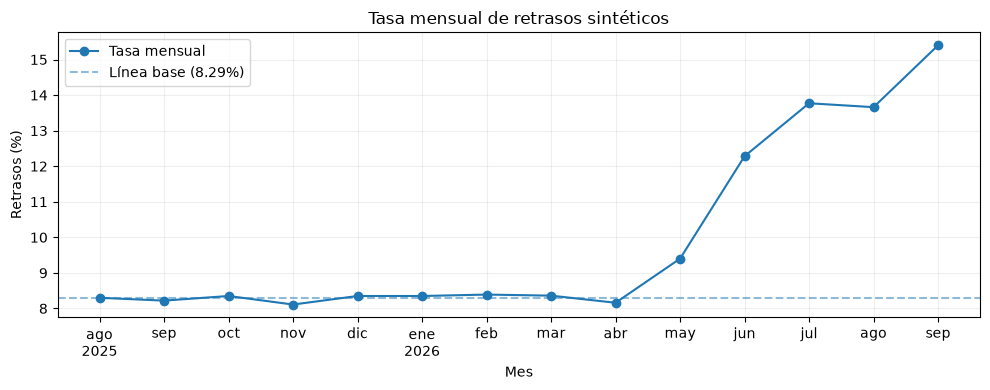

In [30]:
meses_es = ['ene','feb','mar','abr','may','jun','jul','ago','sep','oct','nov','dic']
etiquetas = []
for i, p in enumerate(mensual.index):
    etiqueta = meses_es[p.month - 1]
    if i == 0 or p.month == 1:
        etiqueta += f'\n{p.year}'
    etiquetas.append(etiqueta)

fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(mensual))
ax.plot(x, mensual.tasa_retraso_pct.values, marker='o', label='Tasa mensual')
ax.axhline(tasa_base, ls='--', alpha=0.5, label=f'Línea base ({tasa_base:.2f}%)')
ax.set_xticks(list(x))
ax.set_xticklabels(etiquetas)
ax.set(title='Tasa mensual de retrasos sintéticos', xlabel='Mes', ylabel='Retrasos (%)')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 4. Distribución territorial

La composición por comuna está impuesta parcialmente por los pesos del generador. Las diferencias en tasas son descriptivas y **no permiten concluir inequidad real**; H2-T3 deberá considerar tamaños muestrales y supuestos.

,operaciones,pct_volumen,tasa_retraso_pct,ic95_inf,ic95_sup
comuna_destino,,,,,
Santiago,156274,14.88,12.86,12.69,13.03
Las Condes,111562,10.62,11.70,11.51,11.89
Maipú,101073,9.63,9.36,9.18,9.54
Providencia,89273,8.50,10.71,10.51,10.92
La Florida,89270,8.50,9.35,9.16,9.54
Puente Alto,78311,7.46,10.54,10.33,10.76
Ñuñoa,78247,7.45,8.12,7.93,8.32
Viña del Mar,55949,5.33,9.68,9.44,9.93
Valparaíso,55820,5.32,10.40,10.15,10.66


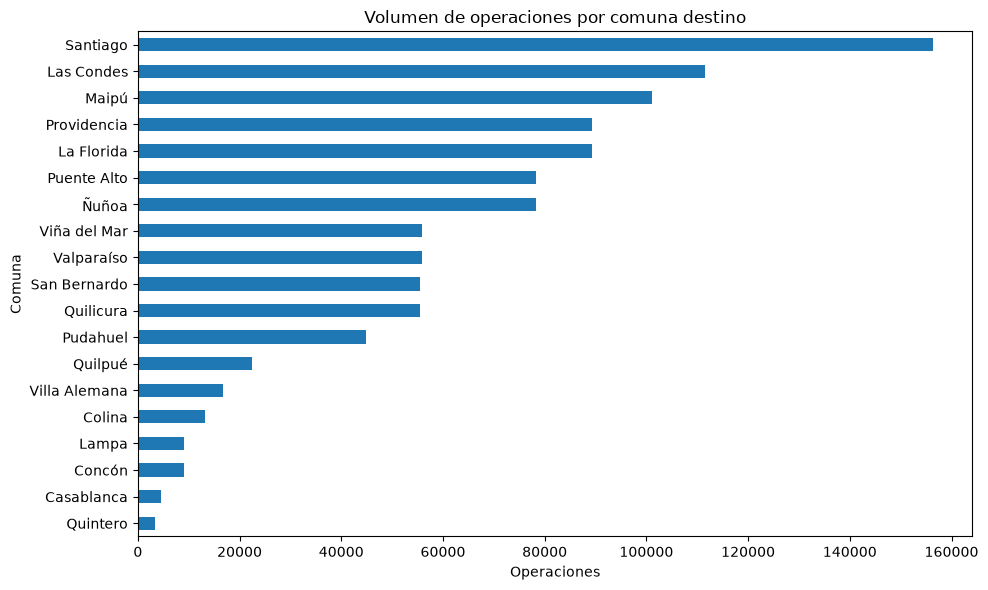

In [23]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return 100*(c-h), 100*(c+h)

territorio = (df.groupby('comuna_destino', observed=True)
              .agg(operaciones=('id_entrega','size'), retrasos=('retraso','sum'))
              .sort_values('operaciones', ascending=False))
territorio['tasa_retraso'] = territorio.retrasos / territorio.operaciones
territorio['tasa_retraso_pct'] = (100*territorio.tasa_retraso).round(2)
ci = territorio.apply(lambda r: wilson(r.retrasos, r.operaciones), axis=1, result_type='expand')
territorio['ic95_inf'], territorio['ic95_sup'] = ci[0].round(2), ci[1].round(2)
territorio['pct_volumen'] = (100*territorio.operaciones/len(df)).round(2)
display(territorio[['operaciones','pct_volumen','tasa_retraso_pct','ic95_inf','ic95_sup']])

fig, ax = plt.subplots(figsize=(10,6))
territorio.operaciones.sort_values().plot(kind='barh', ax=ax)
ax.set(title='Volumen de operaciones por comuna destino', xlabel='Operaciones', ylabel='Comuna')
plt.tight_layout(); plt.show()

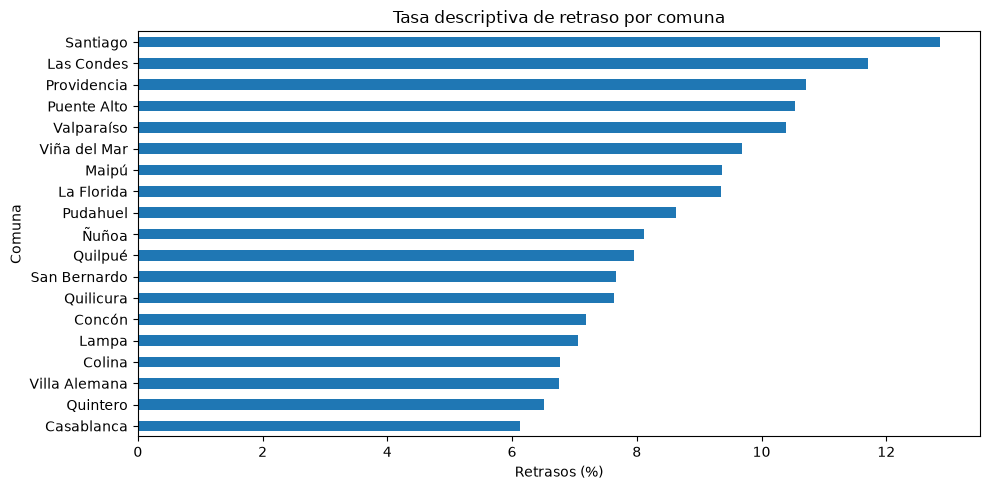

In [24]:
fig, ax = plt.subplots(figsize=(10,5))
territorio.sort_values('tasa_retraso_pct')['tasa_retraso_pct'].plot(kind='barh', ax=ax)
ax.set(title='Tasa descriptiva de retraso por comuna', xlabel='Retrasos (%)', ylabel='Comuna')
plt.tight_layout(); plt.show()

In [25]:
conductores = df.groupby('id_conductor').agg(operaciones=('id_entrega','size'),
                                             comunas_distintas=('comuna_destino','nunique'))
conductores['pct_comuna_principal'] = (100*df.groupby('id_conductor').comuna_destino
    .agg(lambda s: s.value_counts(normalize=True).iloc[0])).round(1)
print(f"Conductores: {len(conductores)}")
display(conductores.describe().round(1).T)

Conductores: 600


,count,mean,std,min,25%,50%,75%,max
operaciones,600.0,1750.0,361.6,1104.0,1402.8,1844.0,2092.2,2451.0
comunas_distintas,600.0,2.5,0.5,2.0,2.0,3.0,3.0,3.0
pct_comuna_principal,600.0,44.4,8.6,33.5,35.8,42.2,52.3,64.4


## 5. Variables operacionales y relación descriptiva con el retraso

Este análisis permite plantear hipótesis para H3/H4, **no demuestra causalidad**. `retraso_salida_min`, `duracion_real_min`, `incidencias` y `estado_final` no deben incorporarse como predictores previos al despacho.

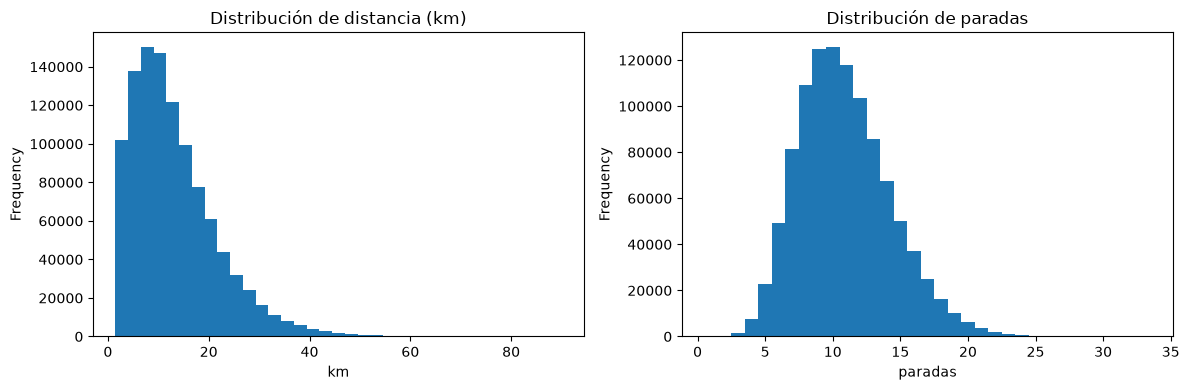

,operaciones,tasa_pct
tipo_vehiculo,,
Camioneta,314536,9.57
Camión,104934,14.09
Furgón,399847,9.95
Moto,230683,8.52


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['distancia_km'].plot(kind='hist', bins=35, ax=axes[0], title='Distribución de distancia (km)')
# Paradas son enteras: una caja por valor, centrada en cada entero
bins_paradas = np.arange(df['n_paradas'].min() - 0.5, df['n_paradas'].max() + 1.5, 1)
df['n_paradas'].plot(kind='hist', bins=bins_paradas, ax=axes[1], title='Distribución de paradas')
axes[0].set_xlabel('km'); axes[1].set_xlabel('paradas')
plt.tight_layout(); plt.show()

por_vehiculo = df.groupby('tipo_vehiculo').agg(operaciones=('retraso','size'), tasa=('retraso','mean'))
por_vehiculo['tasa_pct'] = (100*por_vehiculo.tasa).round(2)
display(por_vehiculo[['operaciones','tasa_pct']])

,operaciones,tasa_pct
distancia_km,,
"(1.499, 6.0]",210010,6.81
"(6.0, 9.6]",215320,7.81
"(9.6, 13.5]",206484,9.01
"(13.5, 19.3]",208986,10.63
"(19.3, 90.0]",209200,15.47


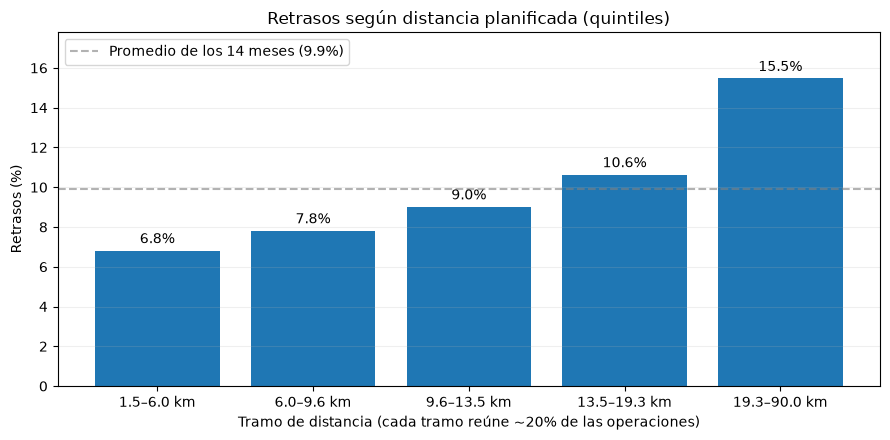

In [33]:
# Tasas descriptivas por tramos, sin entrenar modelos.
tramos = pd.qcut(df.distancia_km, q=5, duplicates='drop')
por_distancia = (df.groupby(tramos, observed=True)
                 .agg(operaciones=('retraso','size'), tasa_retraso=('retraso','mean')))
por_distancia['tasa_pct'] = (100*por_distancia.tasa_retraso).round(2)
display(por_distancia[['operaciones','tasa_pct']])

tasa_global = 100*df.retraso.mean()
etiquetas = [f"{iv.left:.1f}–{iv.right:.1f} km" for iv in por_distancia.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(etiquetas, por_distancia.tasa_pct.values)
ax.bar_label(barras, fmt='%.1f%%', padding=3)
ax.axhline(tasa_global, ls='--', alpha=0.6, color='gray', label=f'Promedio de los 14 meses ({tasa_global:.1f}%)')
ax.set(title='Retrasos según distancia planificada (quintiles)',
       xlabel='Tramo de distancia (cada tramo reúne ~20% de las operaciones)',
       ylabel='Retrasos (%)')
ax.set_ylim(0, por_distancia.tasa_pct.max()*1.15)
ax.legend(); ax.grid(axis='y', alpha=0.2); plt.tight_layout(); plt.show()

**Línea de referencia del gráfico (9,9%):** es el porcentaje de operaciones retrasadas sobre **todo el dataset**: 104.311 operaciones con retraso de 1.050.000 en total, es decir, 9,93%. En el código es `df.retraso.mean()`, porque `retraso` vale 1 o 0 y su promedio es la proporción de retrasos.

Ojo con cómo leerla: **mezcla los 14 meses**. Nueve meses de línea base (~8,3%) y cinco meses con el alza (hasta 15,4%) se promedian en un 9,9% que no describe ningún momento real. No es la tasa de hoy, que ronda el 15%, ni la de antes del alza. Como referencia para comparar tramos de distancia sirve igual, porque todos los quintiles están calculados sobre el mismo período, pero conviene que el gráfico lo diga.


**Distancia:** la tasa de retraso crece de forma sostenida con la distancia planificada, de 6,8 % en el quintil más corto a 15,5 % en el más largo (2,3 veces). El salto se concentra en el último tramo (19,3–90 km), que es muy heterogéneo.

Esta relación es descriptiva y no debe leerse como un hallazgo sobre el comportamiento real de LOGISMART: la distancia participa directamente en el mecanismo generador del retraso en la simulación (H2-T1). El EDA confirma una relación incorporada en los datos sintéticos, no la descubre. Su efecto se evaluará en el modelado (H4).

**Nota para H3:** `id_entrega` no sigue el orden cronológico (los registros están mezclados en el tiempo). Para validación temporal se debe ordenar por `fecha`, no por ID.

## 6. Hallazgos y decisiones documentables

**Interpretar después de ejecutar todas las celdas:**

1. **Cobertura y escala:** el dataset tiene 1.050.000 operaciones en 14 meses (58,3% de los 1,8 M del caso). El promedio de ~75.000 operaciones/mes es una decisión de simulación, no una estimación externa.
2. **Tendencia temporal:** la tasa de línea base (ago 2025–abr 2026) es 8,29 %, la acumulada de los 14 meses es 9,93 % y la de septiembre de 2026 es 15,40 %. Son tres referencias distintas. El incremento proviene del mecanismo sintético.
3. **Calidad:** reportar valores faltantes, duplicados e integridad de `id_entrega`. Definir posibles reglas de imputación **en H3**, no aquí.
4. **Territorio:** las comunas con menor participación (por ejemplo Quintero, 0,3 % del volumen, y Casablanca, 0,4 %) tienen una representación reducida y pocos eventos de retraso. Los intervalos de confianza cuantifican la incertidumbre de sus tasas, pero no descartan otros problemas estadísticos ni la presencia de sesgo. Las diferencias territoriales y su impacto en el modelado se evaluarán en H2-T3 y H3-T3.
5. **Preparación para modelado:** excluir campos posteriores a la entrega y usar validación temporal ordenando por `fecha`; el notebook de modelado documentará la lista exacta de predictores.

**Resultado esperado de H2-T2:** EDA reproducible, diccionario de variables, tablas y gráficos interpretables. Las afirmaciones de desempeño predictivo quedan pendientes para H4/H5.

In [28]:
print('RESUMEN AUTOMÁTICO — H2-T2')
print(f'- Registros: {len(df):,}; columnas: {df.shape[1]}; meses: {len(mensual)}')
print(f'- Tasa global de retrasos: {100*df.retraso.mean():.2f}%')
print(f'- Entregas mensuales: mínimo {mensual.operaciones.min():,}, máximo {mensual.operaciones.max():,}')
print(f'- Variación línea base a último mes: {tasa_base:.2f}% → {ultimo.tasa_retraso_pct:.2f}%')
print('- Nulos detectados:')
for variable, fila in calidad.iterrows():
    print(f"  {variable}: {int(fila['nulos']):,} ({fila['porcentaje_nulos']:.2f}%)")
print(f'- Comunas: {territorio.shape[0]}')
print('- Nota: resultados sintéticos; la evaluación de calidad y diferencias territoriales se detalla en las secciones 7 a 10.')

RESUMEN AUTOMÁTICO — H2-T2
- Registros: 1,050,000; columnas: 21; meses: 14
- Tasa global de retrasos: 9.93%
- Entregas mensuales: mínimo 74,590, máximo 75,405
- Variación línea base a último mes: 8.29% → 15.40%
- Nulos detectados:
  experiencia_conductor_anios: 15,808 (1.51%)
  peso_kg: 10,573 (1.01%)
- Comunas: 19
- Nota: resultados sintéticos; falta evaluación detallada H2-T3.


---

# H2-T3 — Evaluación de calidad de datos y diferencias territoriales

**Propósito:** cuantificar cobertura territorial, faltantes por comuna y variaciones en la tasa de retraso; identificar riesgos que deberán verificarse al preparar y entrenar el modelo. Los resultados describen **datos sintéticos** y no acreditan discriminación, causalidad ni sesgo real de la empresa.

**Criterio de lectura:** una comuna con menos registros no es necesariamente una comuna perjudicada. Las tasas descriptivas reflejan tanto supuestos del generador (por ejemplo congestión) como composición operacional y variabilidad aleatoria. No se modifica `df`.

## 7. Cobertura y completitud por comuna

Se calcula la cantidad de operaciones, el peso relativo en el dataset y los faltantes de las dos variables que pueden contener nulos. Esto permite detectar segmentos menos representados sin inventar un umbral universal de calidad.

In [34]:
variables_con_nulos = ['experiencia_conductor_anios', 'peso_kg']
reporte_comunas = (
    df.groupby('comuna_destino', observed=True)
      .agg(operaciones=('id_entrega', 'size'),
           retrasos=('retraso', 'sum'),
           tasa_retraso=('retraso', 'mean'))
)
reporte_comunas['participacion_pct'] = 100 * reporte_comunas['operaciones'] / len(df)

for variable in variables_con_nulos:
    faltantes = df[variable].isna().groupby(df['comuna_destino']).sum()
    reporte_comunas[f'nulos_{variable}'] = faltantes
    reporte_comunas[f'nulos_{variable}_pct'] = (
        100 * faltantes / reporte_comunas['operaciones']
    )

reporte_comunas['tasa_retraso_pct'] = 100 * reporte_comunas['tasa_retraso']
reporte_comunas = reporte_comunas.sort_values('operaciones')
columnas_cobertura = [
    'operaciones', 'participacion_pct', 'tasa_retraso_pct',
    'nulos_experiencia_conductor_anios_pct', 'nulos_peso_kg_pct'
]
display(reporte_comunas[columnas_cobertura].round(2))
print(f"Comuna con menor volumen: {reporte_comunas.index[0]} "
      f"({int(reporte_comunas['operaciones'].iloc[0]):,} operaciones)")
print(f"Participación de las 5 comunas menores: "
      f"{reporte_comunas['participacion_pct'].head(5).sum():.2f}%")
print('Nota: una participación baja es una alerta de cobertura, no prueba de inequidad.')

,operaciones,participacion_pct,tasa_retraso_pct,nulos_experiencia_conductor_anios_pct,nulos_peso_kg_pct
comuna_destino,,,,,
Quintero,3341,0.32,6.52,1.35,1.35
Casablanca,4460,0.42,6.12,1.43,0.94
Concón,9012,0.86,7.18,1.15,1.03
Lampa,9068,0.86,7.06,1.50,1.05
Colina,13282,1.26,6.77,1.47,1.00
Villa Alemana,16674,1.59,6.75,1.52,0.95
Quilpué,22356,2.13,7.96,1.48,1.06
Pudahuel,44917,4.28,8.63,1.51,0.98
Quilicura,55534,5.29,7.63,1.57,1.03


Comuna con menor volumen: Quintero (3,341 operaciones)
Participación de las 5 comunas menores: 3.73%
Nota: una participación baja es una alerta de cobertura, no prueba de inequidad.


## 8. Comparación de tasas y precisión descriptiva

Para interpretar las tasas territoriales utilizamos intervalos de Wilson del 95 % ya calculados en H2-T2. En muestras grandes los intervalos pueden ser estrechos incluso cuando la composición de los datos no representa adecuadamente la operación real. Las comparaciones son **descriptivas y sin ajuste causal**.

,operaciones,pct_volumen,tasa_retraso_pct,ic95_inf,ic95_sup,ancho_ic_pp,diferencia_global_pp
comuna_destino,,,,,,,
Quintero,3341,0.32,6.52,5.74,7.41,1.67,-3.41
Casablanca,4460,0.42,6.12,5.45,6.86,1.41,-3.81
Concón,9012,0.86,7.18,6.66,7.73,1.07,-2.75
Lampa,9068,0.86,7.06,6.55,7.60,1.05,-2.87
Colina,13282,1.26,6.77,6.35,7.21,0.86,-3.16
Villa Alemana,16674,1.59,6.75,6.38,7.14,0.76,-3.18
Quilpué,22356,2.13,7.96,7.61,8.32,0.71,-1.97
Pudahuel,44917,4.28,8.63,8.38,8.89,0.51,-1.30
Quilicura,55534,5.29,7.63,7.42,7.86,0.44,-2.30


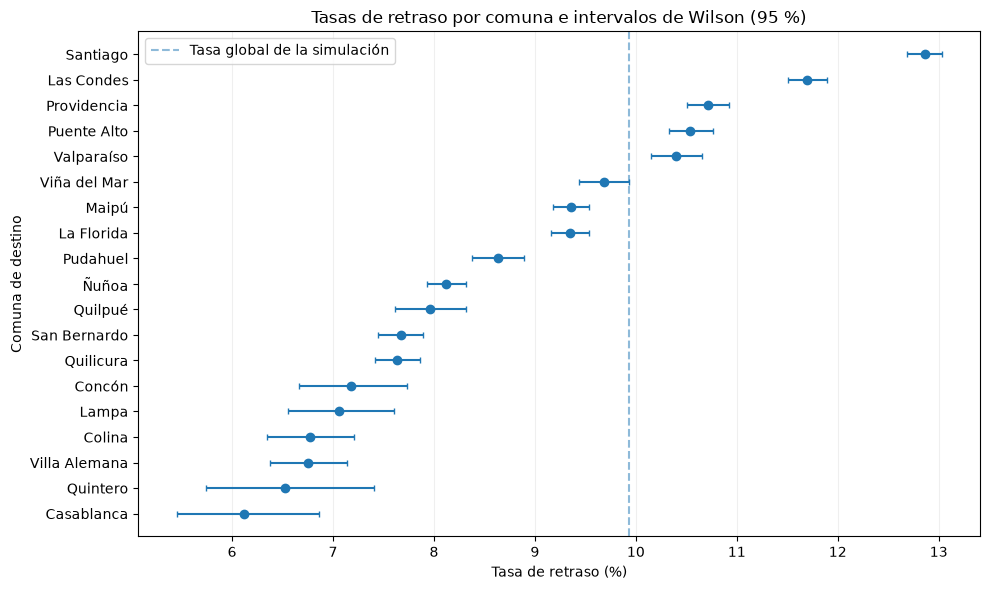

In [35]:
comparacion = territorio[['operaciones', 'pct_volumen', 'tasa_retraso_pct', 'ic95_inf', 'ic95_sup']].copy()
comparacion['ancho_ic_pp'] = comparacion['ic95_sup'] - comparacion['ic95_inf']
comparacion['diferencia_global_pp'] = comparacion['tasa_retraso_pct'] - 100 * df['retraso'].mean()
comparacion = comparacion.sort_values('operaciones')
display(comparacion.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
orden = comparacion.sort_values('tasa_retraso_pct')
valores = orden['tasa_retraso_pct'].to_numpy()
err_izq = valores - orden['ic95_inf'].to_numpy()
err_der = orden['ic95_sup'].to_numpy() - valores
ax.errorbar(valores, orden.index, xerr=np.vstack([err_izq, err_der]),
            fmt='o', capsize=2)
ax.axvline(100 * df['retraso'].mean(), linestyle='--', alpha=0.5,
           label='Tasa global de la simulación')
ax.set(title='Tasas de retraso por comuna e intervalos de Wilson (95 %)',
       xlabel='Tasa de retraso (%)', ylabel='Comuna de destino')
ax.grid(axis='x', alpha=0.2)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 9. Comparación temporal dentro de cada comuna

El aumento general de retrasos entre abril y septiembre de 2026 podría distorsionar una comparación que mezcla los 14 meses. Se resumen tasas por comuna en tres ventanas definidas para esta simulación: línea base (agosto 2025–abril 2026), aumento intermedio (mayo–julio 2026) y período final (agosto–septiembre 2026). Las tasas se muestran solo cuando existe una muestra en el período.

ventana,Base (ago25-abr26),Alza (may-jul26),Final (ago-sep26),cambio_final_base_pp
comuna_destino,,,,
Villa Alemana,5.62,8.18,9.76,4.14
Lampa,5.94,8.00,10.46,4.52
Colina,5.51,8.24,10.16,4.65
San Bernardo,6.39,9.08,11.34,4.95
Quilicura,6.30,9.16,11.39,5.09
Quilpué,6.60,9.34,11.88,5.28
Ñuñoa,6.76,9.60,12.08,5.32
Casablanca,4.97,6.67,10.41,5.44
Pudahuel,7.12,10.36,12.75,5.63


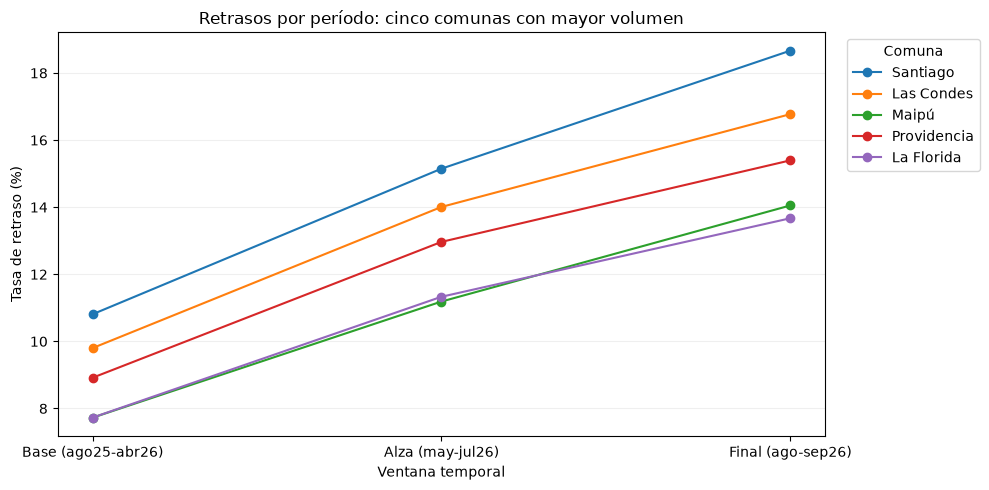

In [37]:
fechas = df['fecha']
ventanas = np.select(
    [fechas < pd.Timestamp('2026-05-01'),
     fechas < pd.Timestamp('2026-08-01')],
    ['Base (ago25-abr26)', 'Alza (may-jul26)'],
    default='Final (ago-sep26)'
)
temporal_comuna = (
    df.assign(ventana=ventanas)
      .groupby(['comuna_destino', 'ventana'], observed=True)
      .agg(operaciones=('retraso','size'), retrasos=('retraso','sum'))
      .reset_index()
)
temporal_comuna['tasa_pct'] = (
    100 * temporal_comuna['retrasos'] / temporal_comuna['operaciones']
)
pivot_temporal = temporal_comuna.pivot(
    index='comuna_destino', columns='ventana', values='tasa_pct'
)
orden_ventanas = ['Base (ago25-abr26)', 'Alza (may-jul26)', 'Final (ago-sep26)']
pivot_temporal = pivot_temporal.reindex(columns=orden_ventanas)
pivot_temporal['cambio_final_base_pp'] = (
    pivot_temporal[orden_ventanas[2]] - pivot_temporal[orden_ventanas[0]]
)
display(pivot_temporal.sort_values('cambio_final_base_pp').round(2))

fig, ax = plt.subplots(figsize=(10, 5))
for comuna in reporte_comunas.sort_values('operaciones', ascending=False).head(5).index:
    fila = pivot_temporal.loc[comuna, orden_ventanas]
    ax.plot(orden_ventanas, fila.to_numpy(), marker='o', label=comuna)
ax.set(title='Retrasos por período: cinco comunas con mayor volumen',
       ylabel='Tasa de retraso (%)', xlabel='Ventana temporal')
ax.legend(title='Comuna', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Hallazgos y decisiones para H3 y H4

El siguiente resumen automatiza los valores descriptivos esenciales. Después de ejecutar el cuaderno completo, se deben revisar las tablas y gráficos antes de redactar conclusiones definitivas.

In [38]:
print('RESUMEN H2-T3 — CALIDAD Y DIFERENCIAS TERRITORIALES')
print(f"Comunas: {len(reporte_comunas)} | Registros: {len(df):,}")
print(f"Menor y mayor participación: "
      f"{reporte_comunas['participacion_pct'].min():.2f}% y "
      f"{reporte_comunas['participacion_pct'].max():.2f}%")
for v in variables_con_nulos:
    pct = 100 * df[v].isna().mean()
    peor = reporte_comunas[f'nulos_{v}_pct'].idxmax()
    peor_pct = reporte_comunas.loc[peor, f'nulos_{v}_pct']
    print(f"Nulos en {v}: {pct:.2f}% global; máximo en {peor}: {peor_pct:.2f}%")
print(f"Tasa de retraso por comuna: "
      f"{comparacion['tasa_retraso_pct'].min():.2f}%–"
      f"{comparacion['tasa_retraso_pct'].max():.2f}% (descriptivo)")
print('No se infiere sesgo discriminatorio ni representatividad poblacional.')

RESUMEN H2-T3 — CALIDAD Y DIFERENCIAS TERRITORIALES
Comunas: 19 | Registros: 1,050,000
Menor y mayor participación: 0.32% y 14.88%
Nulos en experiencia_conductor_anios: 1.51% global; máximo en Quilicura: 1.57%
Nulos en peso_kg: 1.01% global; máximo en Quintero: 1.35%
Tasa de retraso por comuna: 6.12%–12.86% (descriptivo)
No se infiere sesgo discriminatorio ni representatividad poblacional.


### Decisiones documentadas (sin ejecutar transformaciones)

1. **Calidad:** conservar los nulos originales y evaluar en H3-T1 reglas de imputación definidas con datos de entrenamiento, sin utilizar la partición de prueba.
2. **Cobertura:** registrar las diferencias en número de operaciones entre comunas. Un rebalanceo automático no está justificado solo por volúmenes desiguales; H3-T3 deberá considerar si busca predecir el volumen real o mejorar la cobertura de grupos minoritarios.
3. **Sesgos:** las tasas territoriales son descriptivas y pueden estar influidas por congestión, composición operacional y temporalidad configuradas por el generador. No permiten establecer discriminación real.
4. **Validación:** en H4/H5 usar particiones temporales y revisar métricas por comuna, con especial atención a segmentos de menor volumen; evitar conclusiones a partir de tasas globales únicamente.
5. **Trazabilidad:** conservar el dataset sin cambios en `data/raw/` y guardar futuras transformaciones en `data/processed/`.

**Resultado de H2-T3:** evidencia de calidad y comparación territorial. Esta actividad no entrena modelos ni garantiza que se hayan mitigado sesgos.